# Самостоятельная работа

1. Усложните модель(не используйте свёрточные слои, только nn.Linear).
2. Добавьте рассчёт train/val метрик.
3. Обучите модель на наборе данных [CIFAR-10](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.CIFAR10.html).
4. Возьмите более сложный датасет(желательно что бы он был как-то связан с транспортом).
5. Попробуйте обучить модель на нём
6. Посчитайте количество параметров вашей модели.
7. Визуализируйте loss и метрики
8. Проверьте финальное качество своей модели на test выборке.


In [16]:
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets
from torchvision.transforms import v2


Фиксируем сиды, чтобы при перезапуске цифры не скакали.

In [17]:
def set_random_seed(seed):
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    np.random.seed(seed)
    random.seed(seed)


set_random_seed(42)


In [18]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")


Using cuda device


## 1. Модель

В примере из лекции MLP был простой: 784 -> 512 -> 128 -> 10. Делаю его глубже и шире, и чтобы не переписывать архитектуру заново под каждый датасет - пишу один класс, которому на вход передаются размер входа, список размеров скрытых слоёв и число классов. Между слоями добавил Dropout - чтобы не переобучаться на маленьком количестве эпох.

Использую только `nn.Linear`, без свёрточных.

In [19]:
class DeepMLP(nn.Module):
    """
    MLP произвольной глубины: Flatten -> (Linear -> ReLU -> Dropout) * N -> Linear.
    hidden_sizes - список размеров скрытых слоёв.
    """

    def __init__(self, input_dim, hidden_sizes, num_classes, dropout=0.3):
        super().__init__()
        self.flatten = nn.Flatten()

        layers = []
        prev_size = input_dim
        for hidden_size in hidden_sizes:
            layers.append(nn.Linear(prev_size, hidden_size))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout))
            prev_size = hidden_size
        layers.append(nn.Linear(prev_size, num_classes))

        self.layers_stack = nn.Sequential(*layers)

    def forward(self, x):
        x = self.flatten(x)
        return self.layers_stack(x)


def count_parameters(model):
    # просто считаем все обучаемые параметры модели (пункт 6 из задания)
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


## 2. Train/val loop с метриками

В примере из лекции `val_loop` считал accuracy, а `train_loop` - только loss. Добавляю accuracy и на train, и переписываю обе функции в одну универсальную `run_epoch`, которая по флагу `training` либо обучает модель, либо просто считает метрики (для val и test одна и та же функция без обучения).

In [20]:
def run_epoch(dataloader, model, criterion, optimizer=None):
    """
    Один проход по даталоадеру.
    Если оптимизатор есть - это train-режим (считаем градиенты и обновляем веса).
    Если optimizer=None - просто оцениваем модель (val/test), без обучения.
    В конце возвращает средний loss и accuracy за проход.
    """
    is_training = optimizer is not None
    model.train(is_training)

    total_loss = 0.0
    correct = 0
    total = 0

    # torch.no_grad() на val/test экономит память - градиенты там не нужны
    context = torch.enable_grad() if is_training else torch.no_grad()
    with context:
        for imgs, labels in dataloader:
            imgs, labels = imgs.to(device), labels.to(device)

            pred = model(imgs)
            loss = criterion(pred, labels)

            if is_training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * labels.size(0)
            correct += (pred.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    avg_loss = total_loss / total
    accuracy = correct / total
    return avg_loss, accuracy


def fit(model, train_loader, val_loader, criterion, optimizer, num_epochs):
    """Обучает модель num_epochs эпох, возвращает историю loss/accuracy по train и val."""
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoch in range(num_epochs):
        train_loss, train_acc = run_epoch(train_loader, model, criterion, optimizer)
        val_loss, val_acc = run_epoch(val_loader, model, criterion, optimizer=None)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(
            f"Epoch {epoch + 1}/{num_epochs} | "
            f"train loss {train_loss:.4f}, acc {train_acc:.3f} | "
            f"val loss {val_loss:.4f}, acc {val_acc:.3f}"
        )

    return history


def plot_history(history, title=""):
    # два графика рядом: слева loss, справа accuracy
    epochs = range(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(epochs, history["train_loss"], label="train")
    axes[0].plot(epochs, history["val_loss"], label="val")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid()

    axes[1].plot(epochs, history["train_acc"], label="train")
    axes[1].plot(epochs, history["val_acc"], label="val")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid()

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


## 3. CIFAR-10

Грузим. `datasets.CIFAR10` сам скачает данные при `download=True`. Картинки здесь уже цветные 32x32, поэтому при Flatten на входе будет 3 * 32 * 32=3072 признака вместо 784.

In [21]:
transform = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])

cifar_train_full = datasets.CIFAR10(root="./CIFAR10", train=True, download=False, transform=transform)
cifar_test = datasets.CIFAR10(root="./CIFAR10", train=False, download=False, transform=transform)

print("Классы:", cifar_train_full.classes)
print("Train+val размер:", len(cifar_train_full))
print("Test размер:", len(cifar_test))


Классы: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Train+val размер: 50000
Test размер: 10000


Глянем, что вообще в датасете - 5 картинок из train с подписанными классами.

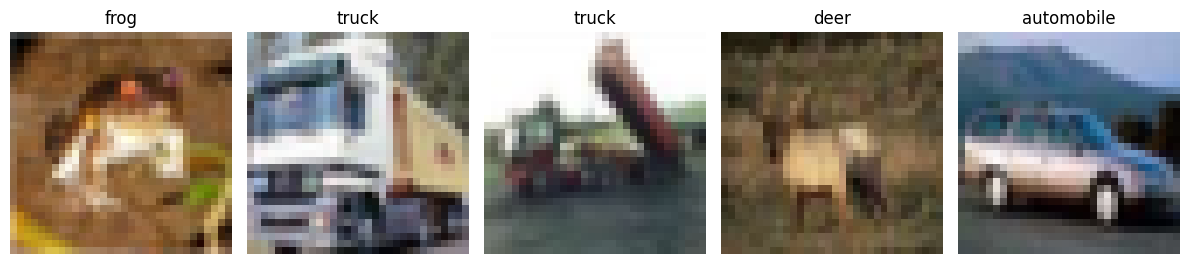

In [22]:
# 5 картинок из train, чтобы посмотреть, с чем работаем
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i, ax in enumerate(axes):
    img, label = cifar_train_full[i]
    ax.imshow(img.permute(1, 2, 0))  # CHW -> HWC, так нужно для imshow
    ax.set_title(cifar_train_full.classes[label])
    ax.axis("off")
plt.tight_layout()
plt.show()


Отделяем валидацию от train (45000/5000), дальше всё как в лекции - свои даталоадеры под train/val/test.

In [23]:
cifar_train, cifar_val = random_split(cifar_train_full, lengths=[45000, 5000])

batch_size = 128

cifar_train_loader = DataLoader(cifar_train, batch_size=batch_size, shuffle=True)
cifar_val_loader = DataLoader(cifar_val, batch_size=batch_size, shuffle=False)
cifar_test_loader = DataLoader(cifar_test, batch_size=batch_size, shuffle=False)


In [24]:
cifar_model = DeepMLP(input_dim=3 * 32 * 32, hidden_sizes=[1024, 512, 256, 128], num_classes=10).to(device)
print(cifar_model)
print("Количество обучаемых параметров:", count_parameters(cifar_model))


DeepMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layers_stack): Sequential(
    (0): Linear(in_features=3072, out_features=1024, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=1024, out_features=512, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=512, out_features=256, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.3, inplace=False)
    (9): Linear(in_features=256, out_features=128, bias=True)
    (10): ReLU()
    (11): Dropout(p=0.3, inplace=False)
    (12): Linear(in_features=128, out_features=10, bias=True)
  )
)
Количество обучаемых параметров: 3837066


Для глубокого MLP Adam сходится надёжнее, чем обычный SGD из примера, поэтому взял его. Эпох ставлю 15 - ставить больше для MLP без свёрток смысла не особо много, он довольно быстро выходит на плато.

In [25]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(cifar_model.parameters(), lr=1e-3)

num_epochs = 15
cifar_history = fit(cifar_model, cifar_train_loader, cifar_val_loader, criterion, optimizer, num_epochs)


Epoch 1/15 | train loss 2.0628, acc 0.213 | val loss 1.8871, acc 0.312
Epoch 2/15 | train loss 1.8935, acc 0.309 | val loss 1.8094, acc 0.335
Epoch 3/15 | train loss 1.8416, acc 0.334 | val loss 1.7540, acc 0.358
Epoch 4/15 | train loss 1.8039, acc 0.348 | val loss 1.7295, acc 0.378
Epoch 5/15 | train loss 1.7811, acc 0.354 | val loss 1.7192, acc 0.381
Epoch 6/15 | train loss 1.7575, acc 0.368 | val loss 1.7007, acc 0.403
Epoch 7/15 | train loss 1.7335, acc 0.375 | val loss 1.6546, acc 0.408
Epoch 8/15 | train loss 1.7159, acc 0.380 | val loss 1.6567, acc 0.403
Epoch 9/15 | train loss 1.7037, acc 0.385 | val loss 1.6438, acc 0.420
Epoch 10/15 | train loss 1.6825, acc 0.393 | val loss 1.6391, acc 0.424
Epoch 11/15 | train loss 1.6690, acc 0.402 | val loss 1.6035, acc 0.425
Epoch 12/15 | train loss 1.6647, acc 0.399 | val loss 1.5932, acc 0.435
Epoch 13/15 | train loss 1.6461, acc 0.409 | val loss 1.5792, acc 0.441
Epoch 14/15 | train loss 1.6414, acc 0.413 | val loss 1.5557, acc 0.447
E

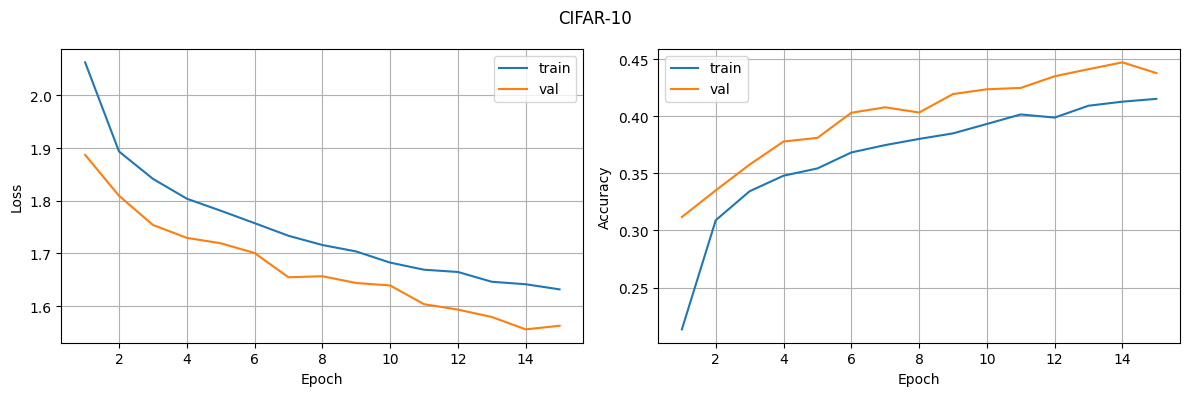

In [26]:
plot_history(cifar_history, title="CIFAR-10")


Финальная проверка на test (его модель не видела ни на train, ни при подборе эпох).

In [27]:
cifar_test_loss, cifar_test_acc = run_epoch(cifar_test_loader, cifar_model, criterion, optimizer=None)
print(f"CIFAR-10 test loss: {cifar_test_loss:.4f}, test accuracy: {cifar_test_acc:.3f}")


CIFAR-10 test loss: 1.5594, test accuracy: 0.441


## 4-5. Транспортный датасет - GTSRB (дорожные знаки)

GTSRB - German Traffic Sign Recognition Benchmark, 43 класса дорожных знаков, "в реальной жизни" с разных ракурсов и расстояний, так что модель должна себя чувствовать сложнее, чем на CIFAR-10. Взял датасет с Kaggle - скачал архив руками и распаковал. Структура там: `Train/<class_id>/*.png` и `Test/*.png` + `Test.csv` с метками для теста.

`torchvision.datasets.ImageFolder` для `Train/` напрямую не подходит: он сортирует имена папок как строки ("0", "1", "10", "11", ..., "2", ...), и класс "10" окажется перепутан с классом "2". Поэтому ниже свой маленький `Dataset` - class_id берёт прямо из имени папки (для train) и из `Test.csv` (для test), без сортировки вслепую.
Картинки там разного размера, поэтому перед Flatten дополнительно привожу всё к одному размеру 32x32 через `v2.Resize`.

In [31]:
import pandas as pd
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset

class GTSRBDataset(Dataset):
    """GTSRB с Kaggle: Train/<class_id>/*.png для train, Test.csv для test."""

    def __init__(self, root, split, transform=None):
        self.transform = transform
        self.samples = []  # (путь до файла, class_id)

        root = Path(root)
        if split == "train":
            for class_dir in sorted((root / "Train").iterdir()):
                if not class_dir.is_dir():
                    continue
                class_id = int(class_dir.name)  # имя папки и есть номер класса
                for img_path in class_dir.glob("*.png"):
                    self.samples.append((img_path, class_id))
        elif split == "test":
            info = pd.read_csv(root / "Test.csv")
            for _, row in info.iterrows():
                self.samples.append((root / row["Path"], int(row["ClassId"])))
        else:
            raise ValueError("split должен быть 'train' или 'test'")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        img = Image.open(img_path).convert("RGB")
        if self.transform is not None:
            img = self.transform(img)
        return img, label



In [33]:
GTSRB_ROOT = r"D:\coding\Studying\CV\Task2\GTSRB"

gtsrb_transform = v2.Compose([
    v2.Resize((32, 32)),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
])

gtsrb_train_full = GTSRBDataset(GTSRB_ROOT, split="train", transform=gtsrb_transform)
gtsrb_test = GTSRBDataset(GTSRB_ROOT, split="test", transform=gtsrb_transform)

print("Train+val размер:", len(gtsrb_train_full))
print("Test размер:", len(gtsrb_test))


Train+val размер: 39209
Test размер: 12630


Валидацию отделяю в пропорции 80/20 (а не фиксированным числом, как для CIFAR-10) - размер GTSRB может немного отличаться от версии к версии.

In [34]:
gtsrb_val_size = int(0.2 * len(gtsrb_train_full))
gtsrb_train_size = len(gtsrb_train_full) - gtsrb_val_size

gtsrb_train, gtsrb_val = random_split(gtsrb_train_full, lengths=[gtsrb_train_size, gtsrb_val_size])

gtsrb_train_loader = DataLoader(gtsrb_train, batch_size=batch_size, shuffle=True)
gtsrb_val_loader = DataLoader(gtsrb_val, batch_size=batch_size, shuffle=False)
gtsrb_test_loader = DataLoader(gtsrb_test, batch_size=batch_size, shuffle=False)


In [35]:
gtsrb_model = DeepMLP(input_dim=3 * 32 * 32, hidden_sizes=[1024, 512, 256, 128], num_classes=43).to(device)
print(gtsrb_model)
print("Количество обучаемых параметров:", count_parameters(gtsrb_model))


DeepMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layers_stack): Sequential(
    (0): Linear(in_features=3072, out_features=1024, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=1024, out_features=512, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=512, out_features=256, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.3, inplace=False)
    (9): Linear(in_features=256, out_features=128, bias=True)
    (10): ReLU()
    (11): Dropout(p=0.3, inplace=False)
    (12): Linear(in_features=128, out_features=43, bias=True)
  )
)
Количество обучаемых параметров: 3841323


Архитектура та же самая (DeepMLP), меняется только число классов на выходе - 43 знака вместо 10 классов CIFAR-10.

In [36]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(gtsrb_model.parameters(), lr=1e-3)

num_epochs = 15
gtsrb_history = fit(gtsrb_model, gtsrb_train_loader, gtsrb_val_loader, criterion, optimizer, num_epochs)


Epoch 1/15 | train loss 2.9083, acc 0.178 | val loss 2.3762, acc 0.268
Epoch 2/15 | train loss 1.9689, acc 0.377 | val loss 1.6098, acc 0.451
Epoch 3/15 | train loss 1.6096, acc 0.473 | val loss 1.2510, acc 0.583
Epoch 4/15 | train loss 1.3857, acc 0.542 | val loss 1.1631, acc 0.587
Epoch 5/15 | train loss 1.2149, acc 0.604 | val loss 0.7961, acc 0.748
Epoch 6/15 | train loss 1.1101, acc 0.639 | val loss 0.9332, acc 0.719
Epoch 7/15 | train loss 1.0396, acc 0.666 | val loss 0.6918, acc 0.776
Epoch 8/15 | train loss 0.9243, acc 0.705 | val loss 0.7687, acc 0.755
Epoch 9/15 | train loss 0.9098, acc 0.711 | val loss 0.6002, acc 0.815
Epoch 10/15 | train loss 0.8344, acc 0.733 | val loss 0.5475, acc 0.822
Epoch 11/15 | train loss 0.7884, acc 0.750 | val loss 0.4499, acc 0.857
Epoch 12/15 | train loss 0.7360, acc 0.767 | val loss 0.5017, acc 0.835
Epoch 13/15 | train loss 0.7204, acc 0.775 | val loss 0.4727, acc 0.853
Epoch 14/15 | train loss 0.6840, acc 0.783 | val loss 0.4712, acc 0.849
E

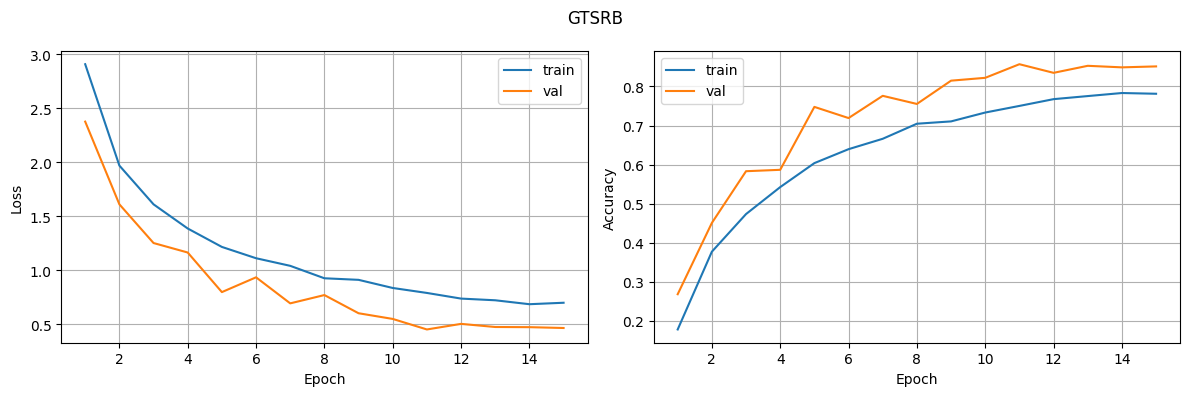

In [37]:
plot_history(gtsrb_history, title="GTSRB")


In [38]:
gtsrb_test_loss, gtsrb_test_acc = run_epoch(gtsrb_test_loader, gtsrb_model, criterion, optimizer=None)
print(f"GTSRB test loss: {gtsrb_test_loss:.4f}, test accuracy: {gtsrb_test_acc:.3f}")


GTSRB test loss: 0.7252, test accuracy: 0.788


## Итог

Модель получилась глубже, чем в примере из лекции (4 скрытых слоя 1024-512-256-128 вместо 2, плюс Dropout), без свёрточных слоёв. На train и val считается не только loss, но и accuracy по каждой эпохе. Обучение прогнано на CIFAR-10 и на GTSRB (дорожные знаки) - с одной и той же архитектурой, меняется только вход/выход под датасет. Для обоих вывели число параметров модели, построили графики loss/accuracy, финальное качество проверено на test, который не участвовал ни в обучении, ни в валидации.
